# Imports

##### standard python libraries

In [1]:
import pandas as pd
from sqlalchemy import create_engine
import netCDF4 as nc
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

In [2]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [3]:
import psql_utilities as psql_utl

### Set Paths

In [4]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'

### Database Connection

In [5]:
db_config = psql_utl.load_config(path_conf_file)
### connect to the database - sqlalchemy
engine = create_engine(db_config['db_uri'])

## Retrieve simulation runs parameters

In metadata schema each Simulation Run is enriched with additional user parameters. Namely, parameters that characterize the information processed by a SR (e.g. Input Dataset, Output Dataset,...) such as input physical parameters, configuration parameters, etc. Simulation run parameters can be used both to retrieve outputs from specific scenarios and to retrieve aggregate information of simulated scenarios. 

In our experiment we have two different types of scenarios, BS-type scenarios and PS-type scenarios, identified by two different set of parameters. <br>
   1. **BS-Scenario Simulation Runs**: each simulation has the following parameters:
    
         - *seismicity_type*: String identiying the type of Scenario, i.e. "BS"
         - *magnitude*: Magnitude of the earthquake event
         - *manning_coeff*: Value of water-bottom friction (Manning coefficient) used in the simulation
         - *fault_centre_lat*: latitude of the centre of the BS-type source fault
         - *fault_centre_lon*: longitude of the centre of the BS-type source fault
         - *fault_centre_depth*: depth of the centre of the BS-type source fault
         - *fault_lenght*: Lenght of the fault
         - *fault_width*: Width of the fault
         - *strike/dip/rake/slip*: value of strike/dip/rake/slip of the fault
    
   2. **PS-Scenario Simulation Runs**: each simulation has the following parameters:
    
         - *seismicity_type*: String identiying the type of Scenario, i.e. "PS"
         - *magnitude*: Magnitude of the earthquake event
         - *manning_coeff*: Value of water-bottom friction (Manning coefficient) used in the simulation
         - *mesh_faults*: 3D multipolygon representing triangular mesh vertices of fault surfaces. Each polygon defines a triangle of the mesh through the coordinate of its 3 vertex coordinates (lat,lon,depth). The number of triangles can differ for each SR.
         - *mesh_faults_bbox*: a 3D bounding box enclosing the mesh fault geometry
         - *mesh_fault_bc_lon*/*mesh_fault_bc_lat*: Latitude/Longitude of the baricenter of the mesh fault
         - *mesh_fault_rake_uniform*: uniform rake angle across the mesh fault 
         - *mesh_fault_slip_distr*: list of values of rake associated to each traingle of the mesh fault
         - *mesh_fault_slip_min*/*mesh_fault_slip_max*/*mesh_fault_slip_avg*: minimum/maximum/average value of the slip distribution of the fault (mesh_fault_slip_distr)

In addition, we have a set of parameters describing the output files of a simulation runs:
  - *max_ts_ct*: max of time series at the site of Catania
  - *arrival_time_ct*: arrival time (seconds) at the site of Catania
  - *max_ts_sr*: max of time series at the site of Siracusa
  - *arrival_time_sr*: arrival time (seconds) at the site of Siracusa

Let us see how one can design queries involving parameters of simulation runs:

  1. First, we select all simulation runs of the experiment
 
  2. Next, we select the relevant parameters each simulation run the required parameters. 

  3. As a result we should obtain a table where for each simulation run we have a unique row with the complete set of parameters. In case a parameter is missing for a simulation run it will appear with a null value. 

The query can be found in *'./query_params.sql'*.

In the present notebook, we perform a query over simulation parameters to have an aggregate view of the scenarios simulated in the dataset: geographical location of the events, distribution of parameters of scenarios and simulation runs. 

### setup

##### read query from file

In [6]:
query_params = open("./query_params.sql", "r")
query_params = query_params.read()

##### set input variables

### query result

##### run query with pandas

In [7]:
df_sr_params = pd.read_sql(query_params, con=engine)
df_sr_params

,sr_id,sr_path,scen_name,fk_sr_id,seismicity_type,magnitude,manning_coeff,fault_centre_lon,fault_centre_lat,fault_centre_depth,...,rake,slip,mesh_fault_bc_lon,mesh_fault_bc_lat,mesh_fault_rake_uniform,mesh_fault_slip_avg,max_ts_ct,max_ts_sr,arrival_time_min_ct,arrival_time_min_sr
0,sr_9,CT-SR_M100/BS_001/E01470N3877E01631N3641-BS-M7...,E01470N3877E01631N3641-BS-M707_E01534N3760_D01...,sr_9,BS,7.07,0.01,15.3446,37.6022,9.135,...,270.0,1.302045,NaN,NaN,NaN,NaN,0.492235,0.103740,6.508274,13.004539
1,sr_11,CT-SR_M100/BS_001/E01267N3753E01646N3535-BS-M7...,E01267N3753E01646N3535-BS-M774_E01551N3692_D10...,sr_11,BS,7.74,0.01,15.5157,36.9278,17.709,...,90.0,5.040772,NaN,NaN,NaN,NaN,0.938407,1.814615,4.010633,2.005317
2,sr_12,CT-SR_M100/BS_001/E01470N3877E01631N3641-BS-M7...,E01470N3877E01631N3641-BS-M754_E01534N3760_D01...,sr_12,BS,7.54,0.01,15.3446,37.6022,14.081,...,270.0,2.236570,NaN,NaN,NaN,NaN,1.028843,0.380830,9.510244,6.508273
3,sr_16,CT-SR_M100/BS_001/E01267N3753E01646N3535-BS-M7...,E01267N3753E01646N3535-BS-M732_E01547N3670_D01...,sr_16,BS,7.32,0.01,15.4790,36.7029,7.167,...,90.0,3.089911,NaN,NaN,NaN,NaN,0.279795,0.452258,11.011229,1.008662
4,sr_25,CT-SR_M100/BS_001/E01108N3882E01527N3690-BS-M7...,E01108N3882E01527N3690-BS-M732_E01506N3760_D11...,sr_25,BS,7.32,0.01,15.0608,37.6022,23.044,...,90.0,1.729640,NaN,NaN,NaN,NaN,0.607877,0.112100,0.000000,6.003942
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
481945,sr_481857,CT-SR_M100/PS_009/E02020N3739E02658N3366-PS-Mu...,E02020N3739E02658N3366-PS-Mur_PYes_Var-M895_E0...,sr_481857,PS,8.95,0.09,NaN,NaN,NaN,...,NaN,NaN,23.86,34.81,90.0,8.146623,2.023531,1.504674,56.001412,51.006165
481946,sr_481901,CT-SR_M100/PS_009/E02020N3739E02658N3366-PS-St...,E02020N3739E02658N3366-PS-Str_PYes_Var-M888_E0...,sr_481901,PS,8.88,0.09,NaN,NaN,NaN,...,NaN,NaN,24.51,34.50,90.0,8.920498,0.876634,0.670558,67.505965,61.502222
481947,sr_481864,CT-SR_M100/PS_009/E02020N3739E02658N3366-PS-St...,E02020N3739E02658N3366-PS-Str_PYes_Var-M895_E0...,sr_481864,PS,8.95,0.09,NaN,NaN,NaN,...,NaN,NaN,23.18,34.71,90.0,10.233136,1.598934,1.252442,58.510518,54.007707
481948,sr_481893,CT-SR_M100/PS_009/E02113N3823E02873N3483-PS-St...,E02113N3823E02873N3483-PS-Str_PYes_Var-M824_E0...,sr_481893,PS,8.24,0.09,NaN,NaN,NaN,...,NaN,NaN,23.49,35.53,90.0,2.686814,0.246848,0.172611,64.505863,59.006274


### Scenarios Stats (BS+PS)

##### Event Location

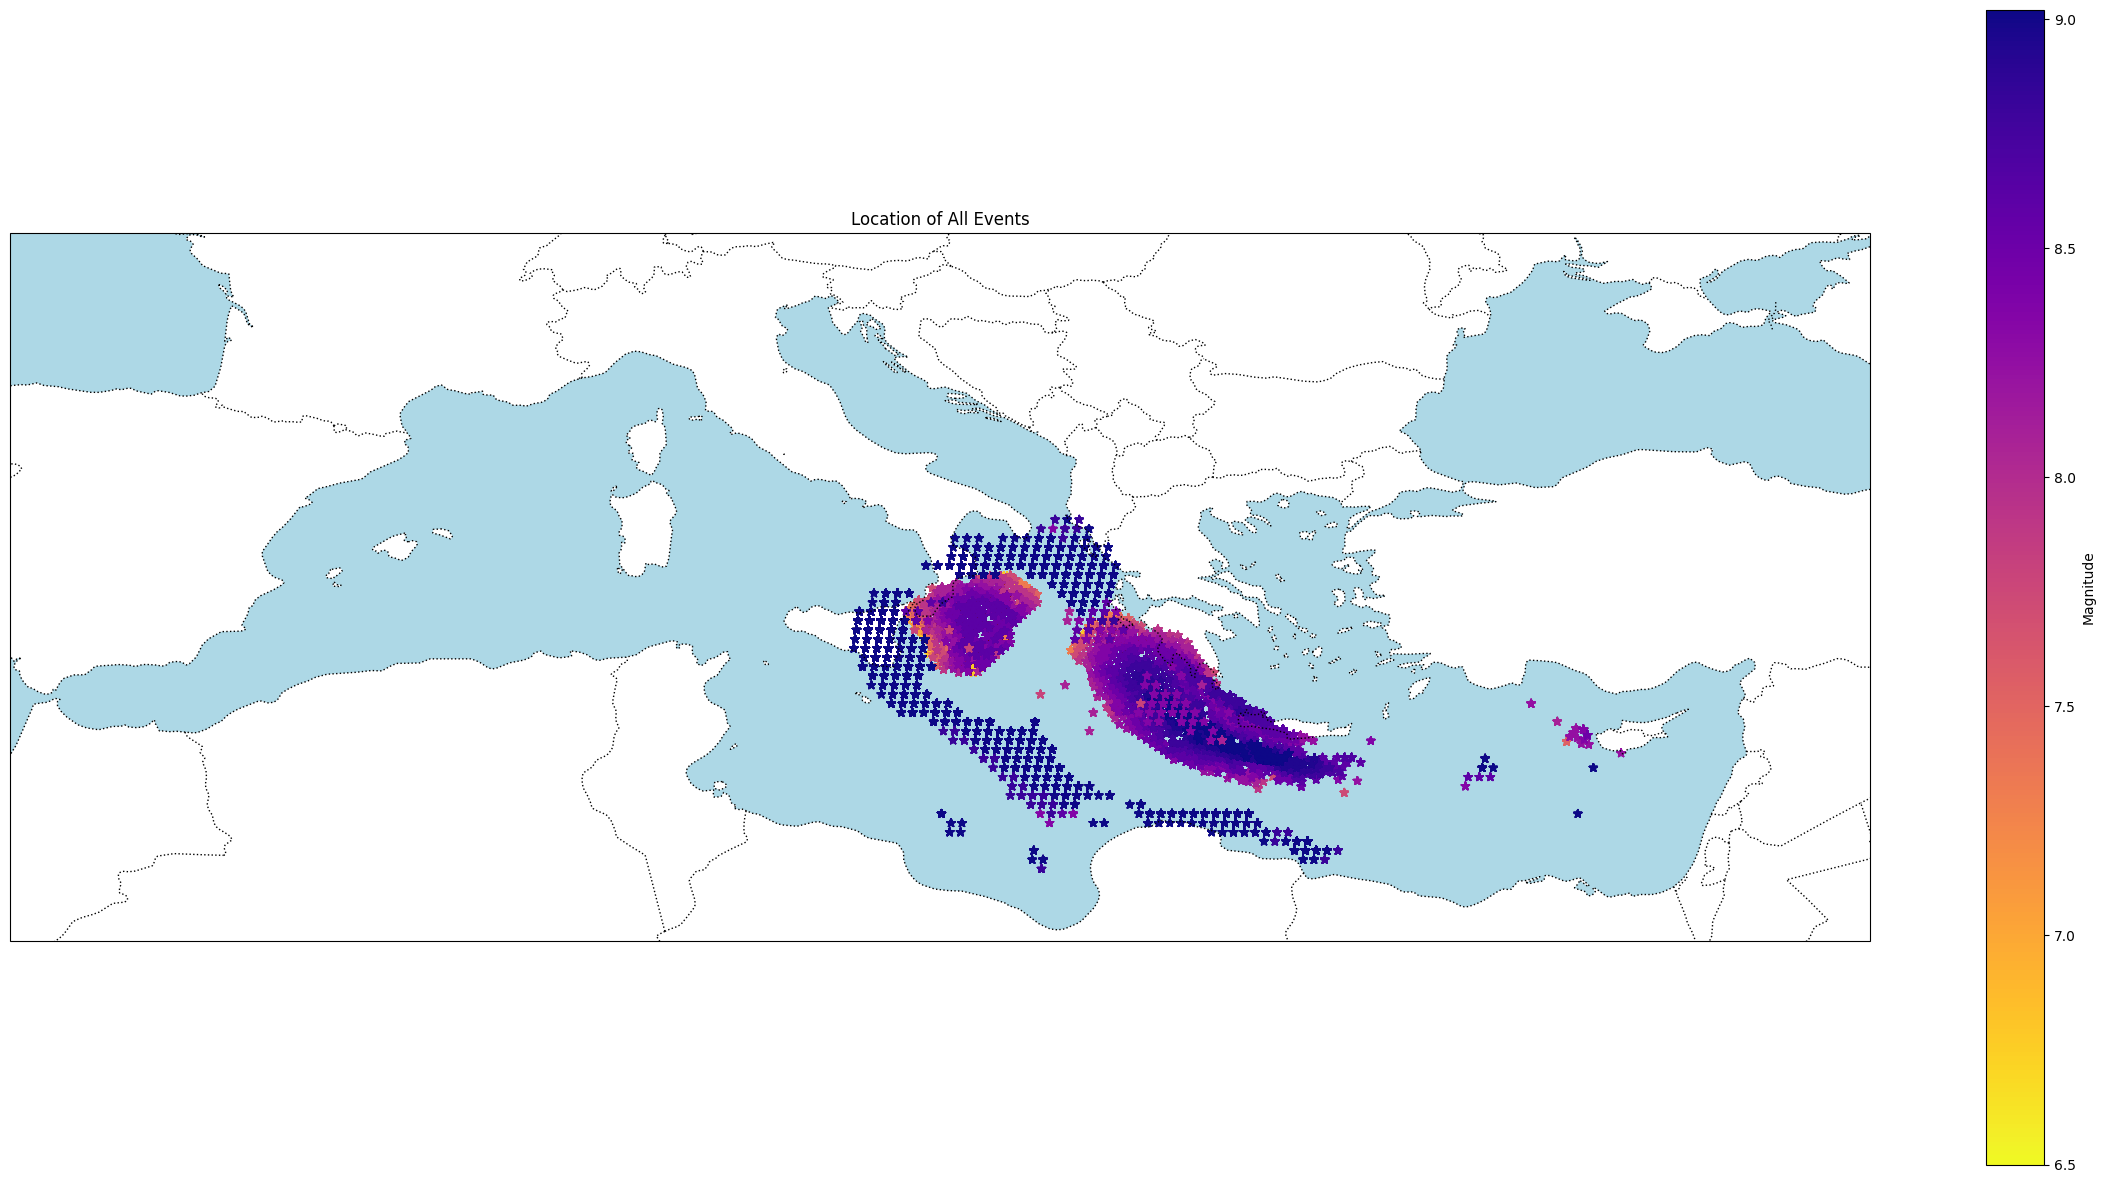

In [8]:
fig, ax = plt.subplots(
            figsize=(30, 15),
            subplot_kw={'projection': ccrs.PlateCarree()}
        )

proj = ccrs.PlateCarree()
ax.add_feature(cfeature.COASTLINE,linestyle=':')
ax.add_feature(cfeature.BORDERS,linestyle=':')
#ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')

cmap_viridis_reversed = plt.get_cmap('plasma').reversed()
#
df_params_ps = df_sr_params[df_sr_params['seismicity_type']=='PS']
df_params_ps = df_params_ps.sort_values(by='magnitude')
#
scatter_ps = ax.scatter(df_params_ps['mesh_fault_bc_lon'].to_list(),df_params_ps['mesh_fault_bc_lat'].to_list(), c=df_params_ps['magnitude'].to_list(),cmap=cmap_viridis_reversed,
            marker='*', 
            transform=proj)
#
#
df_params_bs = df_sr_params[df_sr_params['seismicity_type']=='BS']
df_params_bs = df_params_bs.sort_values(by='magnitude')
#
scatter_bs = ax.scatter(df_params_bs['fault_centre_lon'].to_list(), df_params_bs['fault_centre_lat'].to_list(), c=df_params_bs['magnitude'].to_list(),cmap=cmap_viridis_reversed,
            marker='*', 
            #s = 5 + (list_events_mag**2) * 3,
            #norm=PowerNorm(gamma=0.7),
            transform=proj)
ax.set_extent([-6.5, 39, 30, 45])
ax.set_title('Location of All Events')
#
fig.colorbar(scatter_ps, ax=ax, orientation='vertical', label='Magnitude')


##### event stats

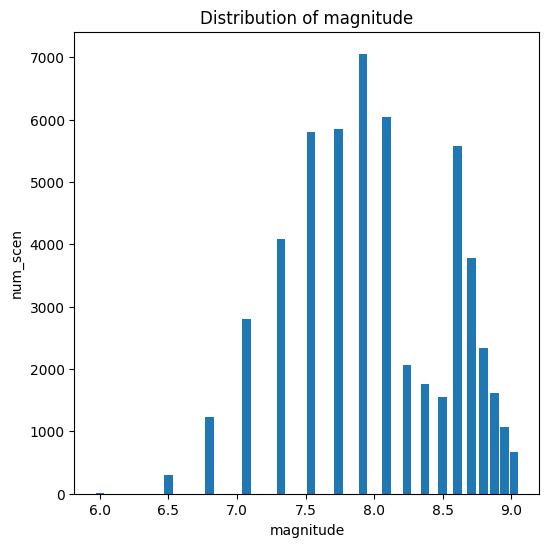

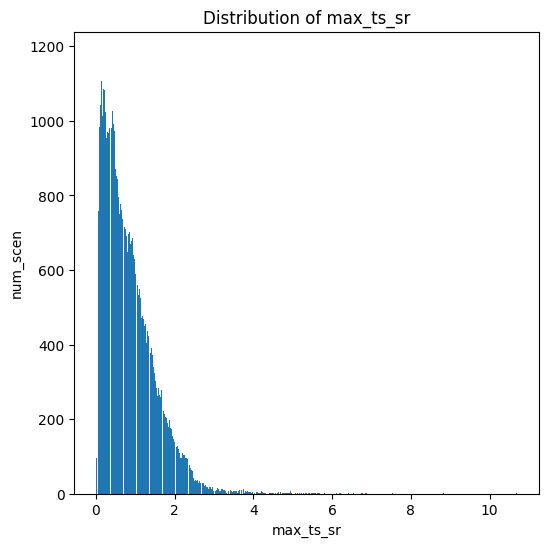

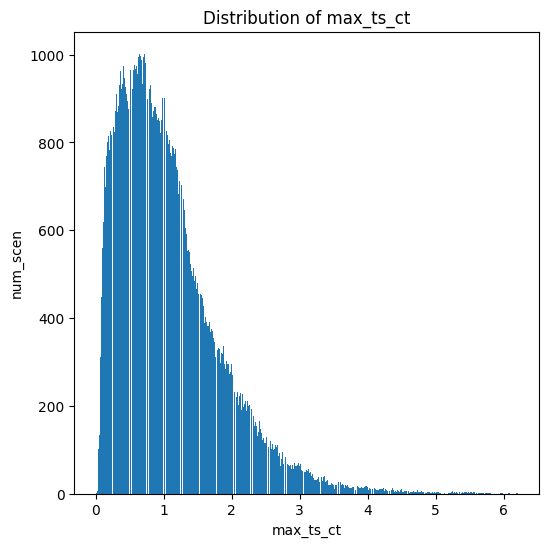

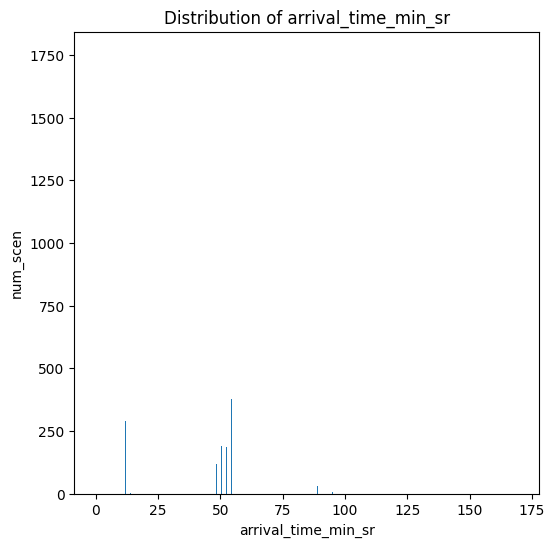

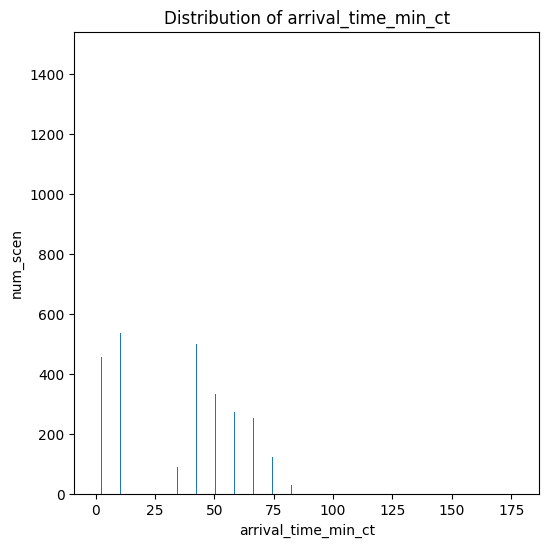

In [9]:
list_params = ['magnitude','max_ts_sr','max_ts_ct','arrival_time_min_sr','arrival_time_min_ct']
#list_params = ['max_ts']
for col_agg in list_params:
    fig, ax = plt.subplots(figsize=(6,6))
    df_agg = df_sr_params.round({col_agg:2}).groupby(by=col_agg).agg(num_sr=('sr_id','count'),
                                                                     num_scen=('scen_name',pd.Series.nunique))\
                                                                .reset_index()\
                                                                .sort_values(by=col_agg)
    width = df_agg[col_agg].diff(periods=1).min()
    width = width-(width/10) if width is not None else 0.001
    ax.bar(df_agg[col_agg],df_agg['num_scen'],width=width)
    ax.set_xlabel(col_agg)
    ax.set_ylabel('num_scen')
    ax.set_title(f"Distribution of {col_agg}")

### Scenarios PS

In [10]:
df_params_ps = df_sr_params[df_sr_params['seismicity_type']=='PS']
df_params_ps = df_params_ps.sort_values(by='magnitude')
df_params_ps.head()

,sr_id,sr_path,scen_name,fk_sr_id,seismicity_type,magnitude,manning_coeff,fault_centre_lon,fault_centre_lat,fault_centre_depth,...,rake,slip,mesh_fault_bc_lon,mesh_fault_bc_lat,mesh_fault_rake_uniform,mesh_fault_slip_avg,max_ts_ct,max_ts_sr,arrival_time_min_ct,arrival_time_min_sr
114536,sr_386531,CT-SR_M100/PS_006/E01548N3896E01854N3659-PS-Mu...,E01548N3896E01854N3659-PS-Mur_PYes_Var-M650_E0...,sr_386531,PS,6.5,0.06,NaN,NaN,NaN,...,NaN,NaN,15.86,37.43,90.0,0.456333,0.023583,0.027161,7.504928,6.003942
297301,sr_415364,CT-SR_M100/PS_007/E01577N3897E01966N3571-PS-St...,E01577N3897E01966N3571-PS-Str_PYes_Var-M650_E0...,sr_415364,PS,6.5,0.07,NaN,NaN,NaN,...,NaN,NaN,17.25,36.79,90.0,0.622200,0.044825,0.082380,23.007107,18.011827
136844,sr_252113,CT-SR_M100/PS_001/E01548N3896E01854N3659-PS-Mu...,E01548N3896E01854N3659-PS-Mur_PYes_Var-M650_E0...,sr_252113,PS,6.5,0.01,NaN,NaN,NaN,...,NaN,NaN,15.86,37.43,90.0,0.456333,0.021902,0.027160,7.504928,6.003942
44784,sr_231319,CT-SR_M100/PS_001/E01548N3896E01854N3659-PS-St...,E01548N3896E01854N3659-PS-Str_PYes_Var-M650_E0...,sr_231319,PS,6.5,0.01,NaN,NaN,NaN,...,NaN,NaN,17.01,36.78,90.0,0.587600,0.047091,0.070595,21.001790,16.006510
135182,sr_228289,CT-SR_M100/PS_001/E01577N3897E01966N3571-PS-St...,E01577N3897E01966N3571-PS-Str_PYes_Var-M650_E0...,sr_228289,PS,6.5,0.01,NaN,NaN,NaN,...,NaN,NaN,17.25,36.79,90.0,0.622200,0.045000,0.082391,23.007107,18.011827


#### Events Location 

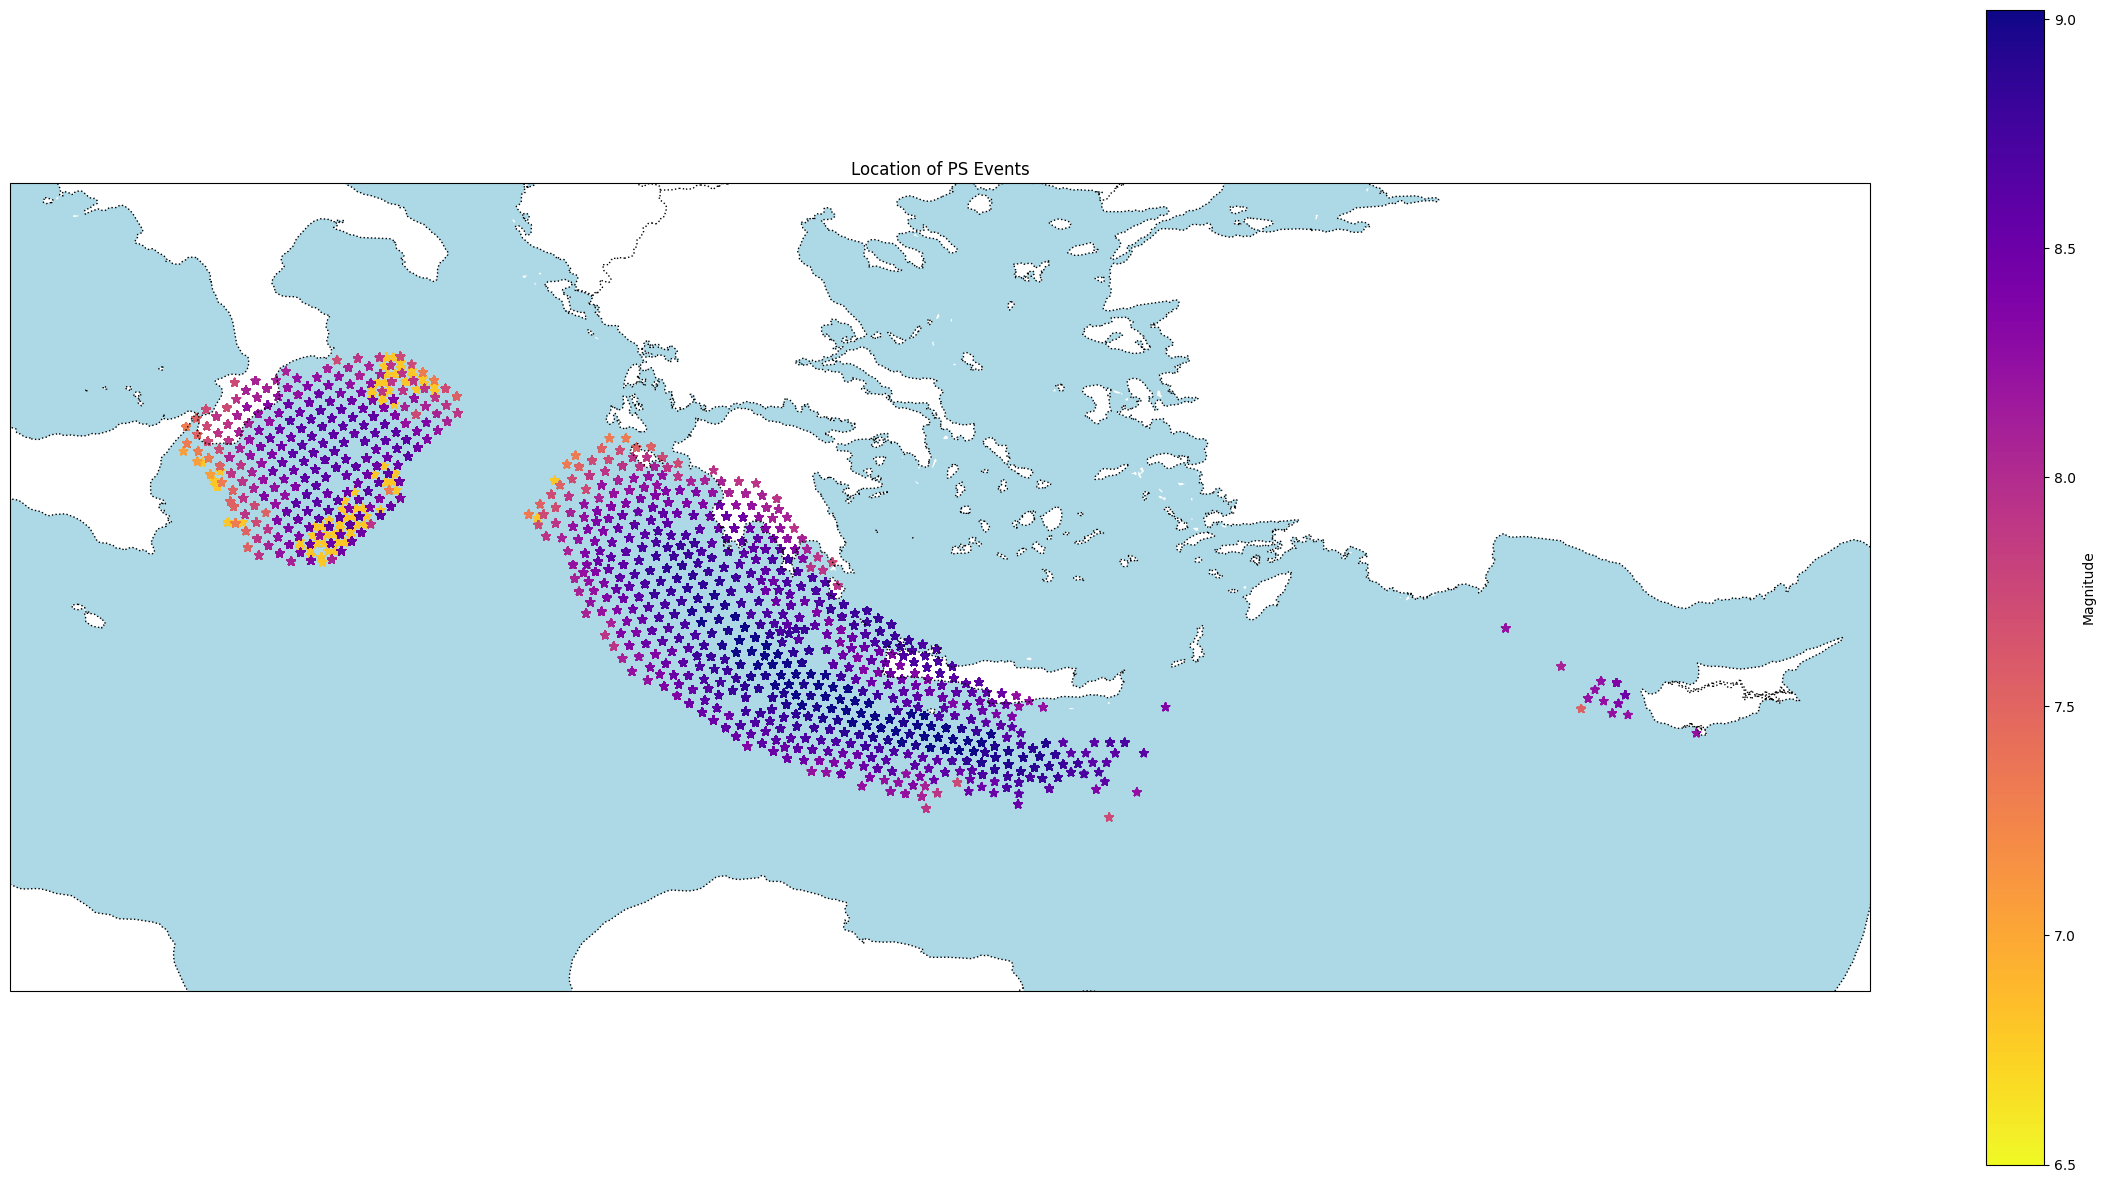

In [11]:
fig, ax = plt.subplots(
            figsize=(30, 15),
            subplot_kw={'projection': ccrs.PlateCarree()}
        )

proj = ccrs.PlateCarree()
ax.add_feature(cfeature.COASTLINE,linestyle=':')
ax.add_feature(cfeature.BORDERS,linestyle=':')
#ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')

cmap_viridis_reversed = plt.get_cmap('plasma').reversed()
scatter = ax.scatter(df_params_ps['mesh_fault_bc_lon'].to_list(),df_params_ps['mesh_fault_bc_lat'].to_list(), c=df_params_ps['magnitude'].to_list(),cmap=cmap_viridis_reversed,
            marker='*', 
            #s = 5 + (list_events_mag**2) * 3,
            #norm=PowerNorm(gamma=0.7),
            transform=proj)
lat_min, lat_max = df_params_ps['mesh_fault_bc_lat'].min(), df_params_ps['mesh_fault_bc_lat'].max()
lon_min, lon_max = df_params_ps['mesh_fault_bc_lon'].min(), df_params_ps['mesh_fault_bc_lon'].max()

padding = 2  # degrees
ax.set_extent([lon_min - padding, lon_max + padding, 
               lat_min - padding, lat_max + padding], 
              crs=ccrs.PlateCarree())
#ax.set_extent([-6.5, 39, 30, 45])
ax.set_title('Location of PS Events')
fig.colorbar(scatter, ax=ax, label='Magnitude')


#### Parameter Distributions

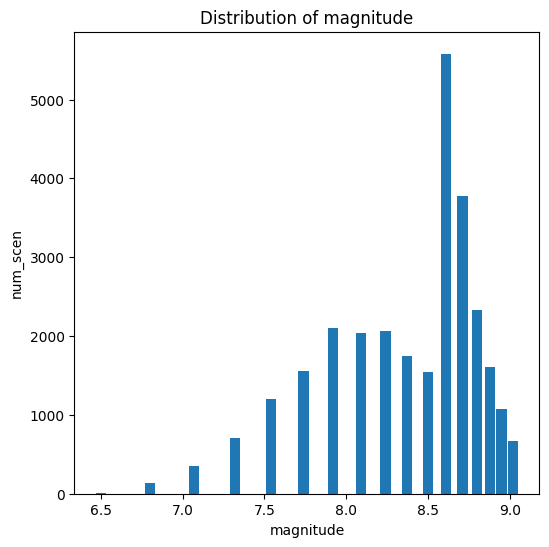

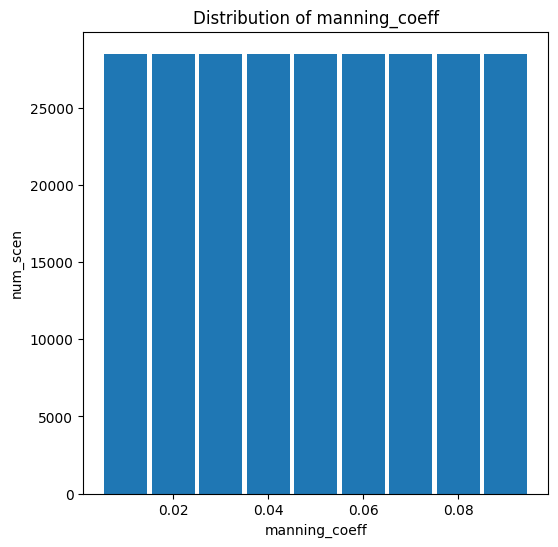

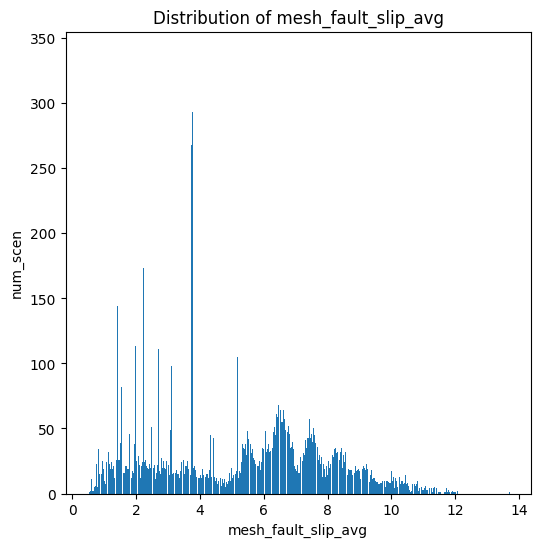

In [12]:
list_cols = ['magnitude','manning_coeff','mesh_fault_slip_avg']

for col_agg in list_cols:
    fig, ax = plt.subplots(figsize=(6,6))
    df_agg = df_params_ps.round({col_agg:2})\
                          .groupby(by=col_agg).agg(num_even=('sr_id','count'),
                                                   num_scen=('scen_name',pd.Series.nunique))\
                                              .reset_index()\
                                              .sort_values(by=col_agg)
    col_count = 'num_scen'
    #def_agg.plot(kind='bar',ax=ax,title=f"distribution of {col_agg}")
    width = df_agg[col_agg].diff(periods=1).min()
    width = width-(width/10) if width is not None else 0.001
    ax.bar(df_agg[col_agg].to_list(), df_agg[col_count].to_list(),width=width)
    #
    ax.set_xlabel(col_agg)
    ax.set_ylabel(col_count)
    ax.set_title(f"Distribution of {col_agg}")

### Scenarios BS

In [13]:
df_params_bs = df_sr_params[df_sr_params['seismicity_type']=='BS']
df_params_bs = df_params_bs.sort_values(by='magnitude')

#### Event Location

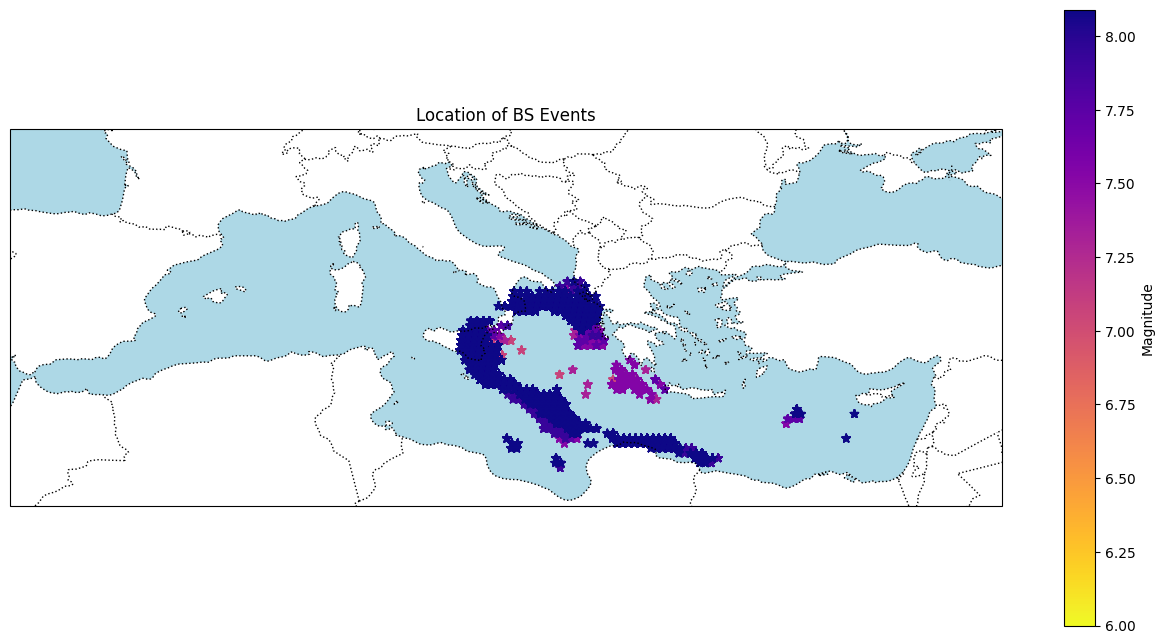

In [14]:
fig, ax = plt.subplots(
            figsize=(16, 8),
            subplot_kw={'projection': ccrs.PlateCarree()}
        )
proj = ccrs.PlateCarree()
ax.add_feature(cfeature.COASTLINE,linestyle=':')
ax.add_feature(cfeature.BORDERS,linestyle=':')
#ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='lightblue')
#
cmap_viridis_reversed = plt.get_cmap('plasma').reversed()
scatter = ax.scatter(df_params_bs['fault_centre_lon'].to_list(), df_params_bs['fault_centre_lat'].to_list(), c=df_params_bs['magnitude'].to_list(),cmap=cmap_viridis_reversed,
            marker='*', 
            #s = 5 + (list_events_mag**2) * 3,
            #norm=PowerNorm(gamma=0.7),
            transform=proj)
ax.set_extent([-6.5, 39, 30, 45])
#
ax.set_title('Location of BS Events')
fig.colorbar(scatter, ax=ax, label='Magnitude')

#### Parameter Distribution

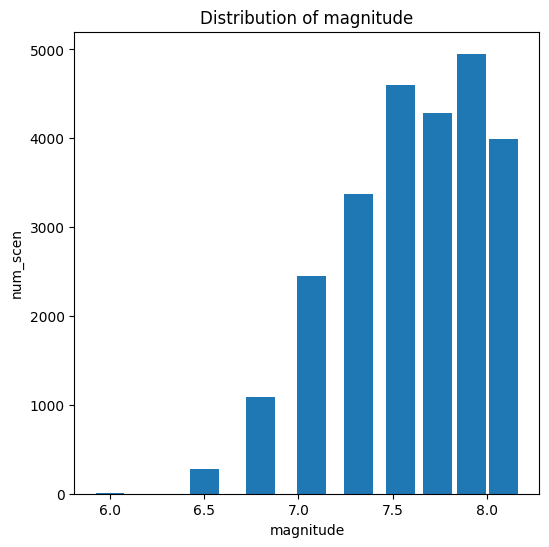

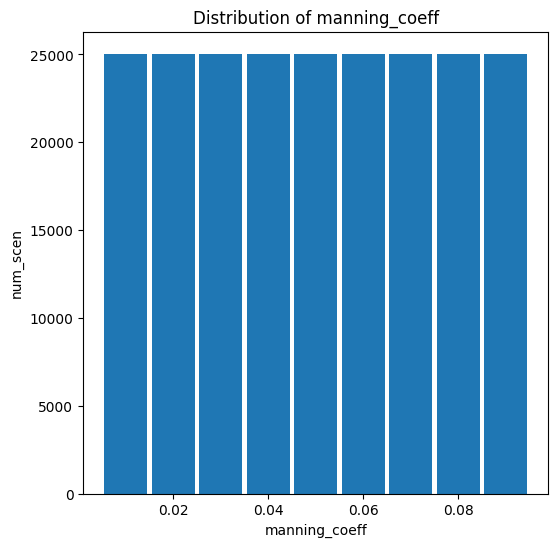

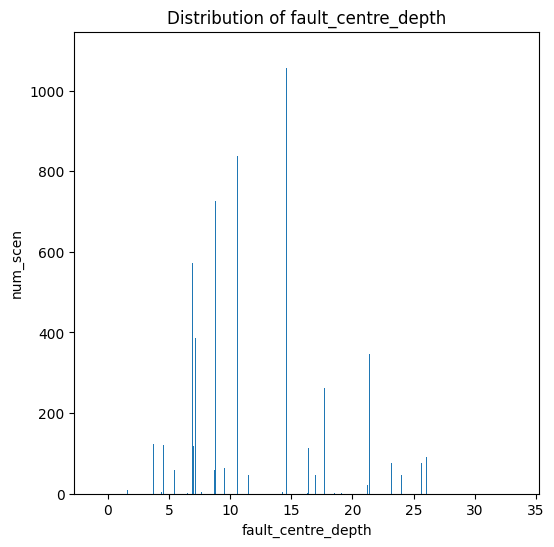

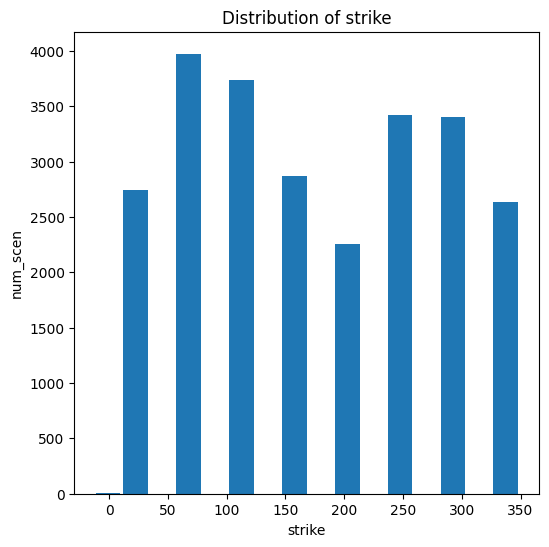

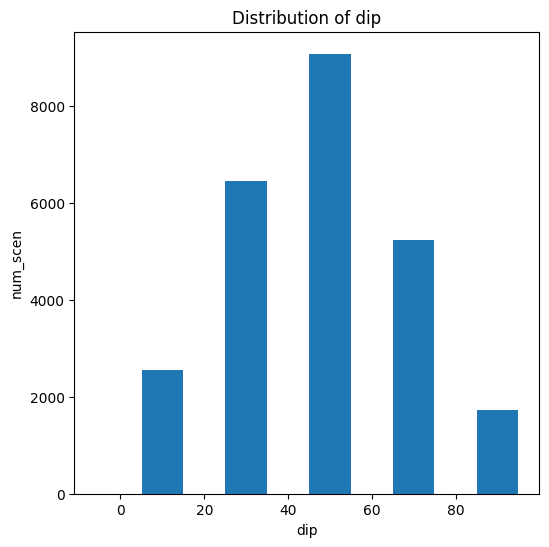

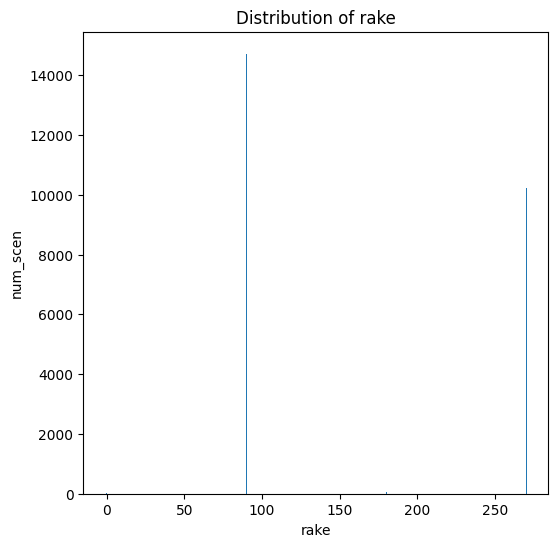

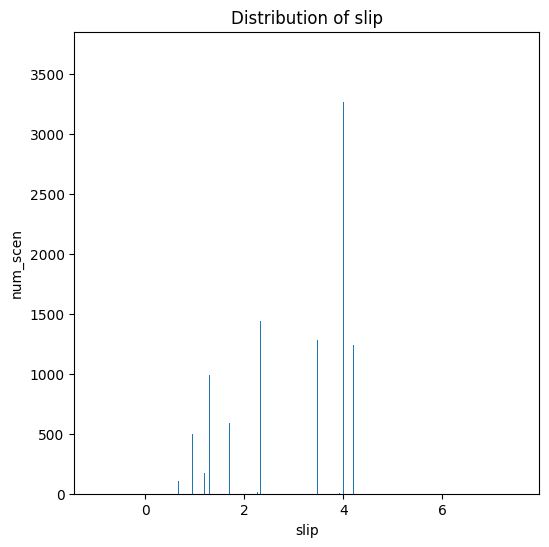

In [16]:
list_cols = ['magnitude','manning_coeff','fault_centre_depth','strike','dip','rake','slip']
for col_agg in list_cols:
    fig, ax = plt.subplots(figsize=(6,6))
    df_agg = df_params_bs.round({col_agg:2})\
                          .groupby(by=col_agg).agg(num_even=('sr_id','count'),
                                                   num_scen=('scen_name',pd.Series.nunique))\
                                              .reset_index()\
                                              .sort_values(by=col_agg)
    col_count = 'num_scen'
    #def_agg.plot(kind='bar',ax=ax,title=f"distribution of {col_agg}")
    width = df_agg[col_agg].diff(periods=1).min()
    width = width-(width/10) if width is not None else 0.001
    ax.bar(df_agg[col_agg].to_list(), df_agg[col_count].to_list(),width=width)
    #
    ax.set_xlabel(col_agg)
    ax.set_ylabel(col_count)
    ax.set_title(f"Distribution of {col_agg}")